In [1]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv("cleaned_housing_data.csv", keep_default_na=False)
manual_data = pd.read_csv("manual_synthetic_data.csv", keep_default_na=False)

In [4]:
df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,12,2008,WD,Normal,250000


In [5]:
manual_data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1268,20,RL,88.9,13032,Pave,NoAlley,IR1,HLS,AllPub,...,0,NoPool,NoFence,NoFeature,0,5,2010,WD,Normal,378500
1,993,60,RL,80.3,9888,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,MnWw,NoFeature,0,7,2007,WD,Normal,187000
2,958,20,RL,70.3,7416,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,4,2007,WD,Normal,132000
3,402,20,RL,64.7,8873,Pave,NoAlley,IR1,Lvl,AllPub,...,0,NoPool,NoFence,NoFeature,0,7,2006,New,Partial,164990
4,726,20,RL,59.5,6714,Pave,NoAlley,Reg,Lvl,AllPub,...,0,NoPool,NoFence,Shed,501,11,2009,WD,Normal,120500


In [7]:
df['MSSubClass'].dtype

dtype('int64')

In [8]:
manual_data['MSSubClass'].dtype

dtype('int64')

In [9]:
df["MSSubClass"] = df["MSSubClass"].astype(str)

manual_data["MSSubClass"] = manual_data["MSSubClass"].astype(str)

print("Original:", df["MSSubClass"].dtype)
print("Synthetic:", manual_data["MSSubClass"].dtype)

Original: str
Synthetic: str


In [10]:
X = df.drop("SalePrice", axis=1)
y = df["SalePrice"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (1168, 80)
X_test: (292, 80)


In [11]:
# Prepare Original and Synthetic Training Data

# Prepare Original Training Data
original_train = X_train.drop("Id", axis=1).copy()
original_train["SalePrice"] = y_train

# Prepare Manual Synthetic Data
synthetic_train = manual_data.drop("Id", axis=1).copy()

print("Original Training Data:", original_train.shape)
print("Synthetic Training Data:", synthetic_train.shape)

Original Training Data: (1168, 80)
Synthetic Training Data: (500, 80)


In [12]:
# Combine Original and Synthetic Training Data
augmented_train = pd.concat([original_train, synthetic_train],ignore_index=True)

print("Original Training Records:", len(original_train))
print("Synthetic Training Records:", len(synthetic_train))
print("Augmented Training Records:", len(augmented_train))
print("Augmented Dataset Shape:", augmented_train.shape)

Original Training Records: 1168
Synthetic Training Records: 500
Augmented Training Records: 1668
Augmented Dataset Shape: (1668, 80)


In [13]:
# Separate Features and Target

# Original Data
X_original = original_train.drop("SalePrice", axis=1)
y_original = original_train["SalePrice"]

# Augmented Data
X_augmented = augmented_train.drop("SalePrice", axis=1)
y_augmented = augmented_train["SalePrice"]

print("Original Features:", X_original.shape)
print("Original Target:", y_original.shape)

print("Augmented Features:", X_augmented.shape)
print("Augmented Target:", y_augmented.shape)

Original Features: (1168, 79)
Original Target: (1168,)
Augmented Features: (1668, 79)
Augmented Target: (1668,)


In [14]:
# Identify Numerical and Categorical Features

# Identify Numerical Features
numerical_features = X_original.select_dtypes(include=["int64", "float64"]).columns.tolist()

# Identify Categorical Features
categorical_features = X_original.select_dtypes(include=["object", "str"]).columns.tolist()

print("Numerical Features:", len(numerical_features))
print("Categorical Features:", len(categorical_features))

print("\nCategorical Columns:")
print(categorical_features)

Numerical Features: 35
Categorical Features: 44

Categorical Columns:
['MSSubClass', 'MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']


In [ ]:
# Create Preprocessing Pipeline

In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

# Create Preprocessor
preprocessor = ColumnTransformer(transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

print("Preprocessor Created Successfully!")

Preprocessor Created Successfully!


In [ ]:
# Train Original Data Model

In [16]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

# Create Original Model Pipeline
original_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Model
original_model.fit(X_original, y_original)

print("Original Data Model Trained Successfully!")

Original Data Model Trained Successfully!


In [17]:
# Train Augmented Data Model

from sklearn.base import clone

# Create a fresh copy of Preprocessor
augmented_preprocessor = clone(preprocessor)

# Create Augmented Model Pipeline
augmented_model = Pipeline(steps=[
    ("preprocessor", augmented_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Train Model
augmented_model.fit(X_augmented, y_augmented)

print("Augmented Data Model Trained Successfully!")

Augmented Data Model Trained Successfully!


In [18]:
# Model Performance Evaluation

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Original Model Predictions
original_predictions = original_model.predict(X_test)

# Augmented Model Predictions
augmented_predictions = augmented_model.predict(X_test)

# Evaluation Function
def evaluate_model(y_true, predictions):
    mae = mean_absolute_error(y_true, predictions)
    rmse = np.sqrt(mean_squared_error(y_true, predictions))
    r2 = r2_score(y_true, predictions)

    return mae, rmse, r2

# Evaluate Both Models
original_results = evaluate_model(y_test, original_predictions)
augmented_results = evaluate_model(y_test, augmented_predictions)

print("Original Model Results:")
print("MAE:", original_results[0])
print("RMSE:", original_results[1])
print("R2 Score:", original_results[2])

print("\nAugmented Model Results:")
print("MAE:", augmented_results[0])
print("RMSE:", augmented_results[1])
print("R2 Score:", augmented_results[2])

Original Model Results:
MAE: 17505.2075
RMSE: 29089.22616433515
R2 Score: 0.889680952806549

Augmented Model Results:
MAE: 17844.76167808219
RMSE: 29481.312603228173
R2 Score: 0.8866869844473022


In [19]:
# Identify Important Features

# Get Feature Names After Preprocessing
feature_names = original_model.named_steps["preprocessor"].get_feature_names_out()

# Get Feature Importance
importance_values = original_model.named_steps["model"].feature_importances_

# Create DataFrame
feature_importance = pd.DataFrame({"Feature": feature_names,"Importance": importance_values})

# Sort Features by Importance
feature_importance = feature_importance.sort_values(by="Importance",ascending=False)

# Display Top 15 Features
print(feature_importance.head(15))

               Feature  Importance
2     num__OverallQual    0.556444
14      num__GrLivArea    0.122748
10    num__TotalBsmtSF    0.034290
12       num__2ndFlrSF    0.030186
7      num__BsmtFinSF1    0.027349
11       num__1stFlrSF    0.026791
1         num__LotArea    0.017700
25     num__GarageArea    0.014785
24     num__GarageCars    0.013979
4       num__YearBuilt    0.012846
0     num__LotFrontage    0.008963
5    num__YearRemodAdd    0.006862
23    num__GarageYrBlt    0.006745
197   cat__BsmtQual_Ex    0.006553
17       num__FullBath    0.006152


In [ ]:
# Compare Feature Importance

In [20]:
# Get Augmented Model Feature Names
augmented_feature_names = augmented_model.named_steps["preprocessor"].get_feature_names_out()

# Get Augmented Model Feature Importance
augmented_importance_values = augmented_model.named_steps["model"].feature_importances_

# Create Augmented Feature Importance DataFrame
augmented_feature_importance = pd.DataFrame({"Feature": augmented_feature_names,"Augmented_Importance": augmented_importance_values})

# Merge Both Model Results
importance_comparison = feature_importance.merge(augmented_feature_importance,on="Feature")

# Rename Original Importance Column
importance_comparison = importance_comparison.rename(columns={"Importance": "Original_Importance"})

# Sort by Original Importance
importance_comparison = importance_comparison.sort_values(by="Original_Importance",ascending=False)

# Display Top 15 Features
print(importance_comparison.head(15))

              Feature  Original_Importance  Augmented_Importance
0    num__OverallQual             0.556444              0.572866
1      num__GrLivArea             0.122748              0.116463
2    num__TotalBsmtSF             0.034290              0.040276
3       num__2ndFlrSF             0.030186              0.019779
4     num__BsmtFinSF1             0.027349              0.032342
5       num__1stFlrSF             0.026791              0.023939
6        num__LotArea             0.017700              0.012657
7     num__GarageArea             0.014785              0.016216
8     num__GarageCars             0.013979              0.012684
9      num__YearBuilt             0.012846              0.009738
10   num__LotFrontage             0.008963              0.007444
11  num__YearRemodAdd             0.006862              0.007478
12   num__GarageYrBlt             0.006745              0.006025
13   cat__BsmtQual_Ex             0.006553              0.015892
14      num__FullBath    

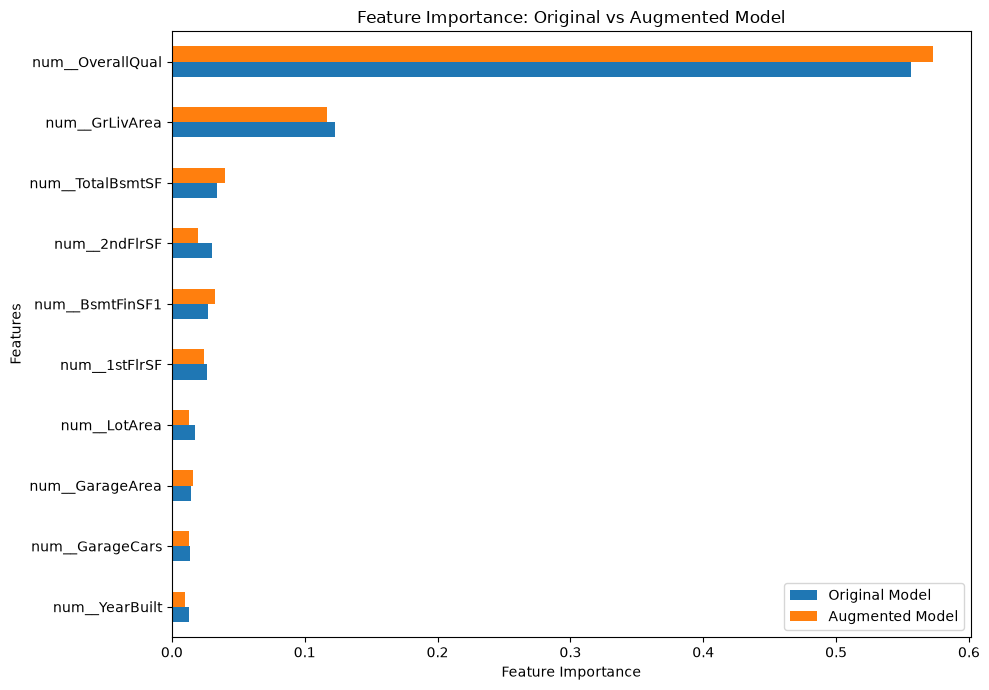

In [21]:
# Visualize Feature Importance

import matplotlib.pyplot as plt

# Select Top 10 Features
top_10 = importance_comparison.head(10).copy()

# Prepare Chart
top_10 = top_10.sort_values(
    by="Original_Importance",
    ascending=True
)

# Create Horizontal Bar Chart
top_10.plot(
    x="Feature",
    y=["Original_Importance", "Augmented_Importance"],
    kind="barh",
    figsize=(10, 7)
)

plt.title("Feature Importance: Original vs Augmented Model")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.legend(["Original Model", "Augmented Model"])
plt.tight_layout()
plt.show()

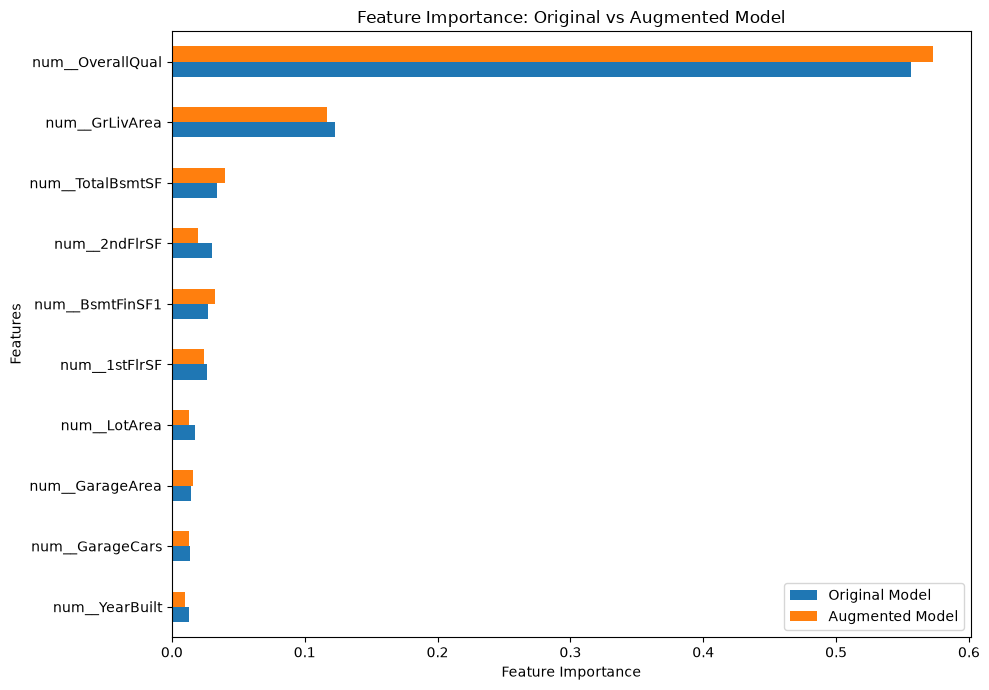

In [22]:
# Save Feature Importance Chart

# Create Feature Importance Chart
top_10.plot(
    x="Feature",
    y=["Original_Importance", "Augmented_Importance"],
    kind="barh",
    figsize=(10, 7)
)

plt.title("Feature Importance: Original vs Augmented Model")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.legend(["Original Model", "Augmented Model"])
plt.tight_layout()

# Save Chart
plt.savefig("feature_importance_comparison.png",dpi=300,bbox_inches="tight")

plt.show()

In [ ]:
# Actual vs Predicted Price Analysis

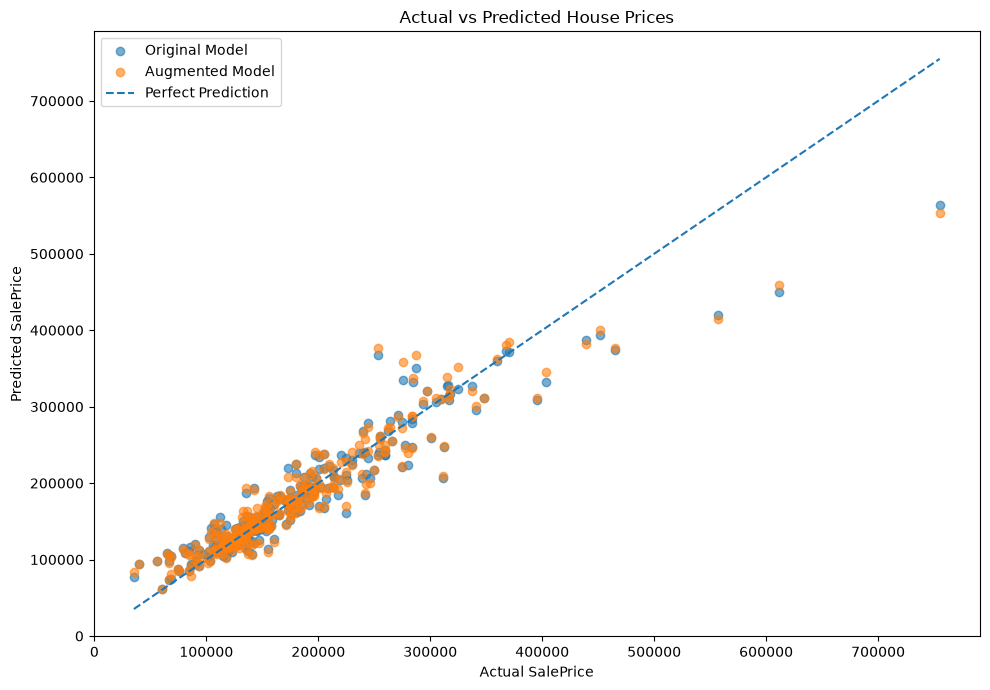

In [23]:
# Create Comparison Chart

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

# Original Model Predictions
plt.scatter(y_test,original_predictions,alpha=0.6,label="Original Model")

# Augmented Model Predictions
plt.scatter(y_test,augmented_predictions,alpha=0.6,label="Augmented Model")

# Perfect Prediction Reference Line
min_price = min(y_test.min(), original_predictions.min(), augmented_predictions.min())
max_price = max(y_test.max(), original_predictions.max(), augmented_predictions.max())

plt.plot([min_price, max_price],[min_price, max_price],linestyle="--",label="Perfect Prediction")

plt.title("Actual vs Predicted House Prices")
plt.xlabel("Actual SalePrice")
plt.ylabel("Predicted SalePrice")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# improve Expensive houses prediction

In [24]:
#Log Transformation of SalePrice

y_transformed = np.log1p(y_train)

In [ ]:
# Residual Analysis

In [25]:
# Calculate Prediction Errors

# Create Residual Analysis DataFrame
residual_data = pd.DataFrame({"Actual_Price": y_test,"Original_Predicted": original_predictions,"Augmented_Predicted": augmented_predictions
}, index=y_test.index)

# Calculate Residuals
residual_data["Original_Residual"] = (residual_data["Actual_Price"] -residual_data["Original_Predicted"])

residual_data["Augmented_Residual"] = (residual_data["Actual_Price"] -residual_data["Augmented_Predicted"])

# Display First 10 Records
print(residual_data.head(10))

      Actual_Price  Original_Predicted  Augmented_Predicted  \
892         154500          140742.935           140772.250   
1105        325000          323104.180           351553.450   
413         115000          115154.000           115428.500   
522         159000          151960.750           158535.000   
1036        315500          328832.505           311926.445   
614          75500           85580.500            84657.000   
218         311500          206540.875           209169.350   
1160        146000          151777.700           152853.060   
649          84500           85148.160            85852.750   
887         135500          131201.305           132157.650   

      Original_Residual  Augmented_Residual  
892           13757.065           13727.750  
1105           1895.820          -26553.450  
413            -154.000            -428.500  
522            7039.250             465.000  
1036         -13332.505            3573.555  
614          -10080.500       

In [26]:
# Analyze Expensive Houses

# Filter Expensive Houses
expensive_houses = residual_data[residual_data["Actual_Price"] >= 400000].copy()

# Sort by Actual Price
expensive_houses = expensive_houses.sort_values(by="Actual_Price",ascending=False)

print(expensive_houses)

      Actual_Price  Original_Predicted  Augmented_Predicted  \
691         755000          563871.730           553216.745   
898         611657          450087.015           459463.940   
1046        556581          419547.970           414687.930   
1243        465000          374602.475           376964.520   
591         451950          393937.810           399712.335   
58          438780          386692.980           381968.400   
231         403000          332134.470           345901.140   

      Original_Residual  Augmented_Residual  
691          191128.270          201783.255  
898          161569.985          152193.060  
1046         137033.030          141893.070  
1243          90397.525           88035.480  
591           58012.190           52237.665  
58            52087.020           56811.600  
231           70865.530           57098.860  


In [27]:
# Calculate Expensive House MAE

original_expensive_mae = (
    expensive_houses["Original_Residual"].abs().mean()
)

augmented_expensive_mae = (
    expensive_houses["Augmented_Residual"].abs().mean()
)

print("Original Expensive House MAE:", original_expensive_mae)

print("Augmented Expensive House MAE:", augmented_expensive_mae)

Original Expensive House MAE: 108727.65000000001
Augmented Expensive House MAE: 107150.42714285714


In [29]:
# Train a Log Transformation Model

from sklearn.base import clone

# Create a separate copy of the preprocessor
log_preprocessor = clone(preprocessor)

# Create Log Transformation Model
log_original_model = Pipeline(steps=[
    ("preprocessor", log_preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1
    ))
])

# Apply Log Transformation on SalePrice
y_original_log = np.log1p(y_original)

# Train the model
log_original_model.fit(X_original, y_original_log)

print("Log Transformation Model Trained Successfully!")

Log Transformation Model Trained Successfully!


In [30]:
# Generate Predictions

# Predict house prices in log scale
log_predictions = log_original_model.predict(X_test)

# Convert predictions back to original price scale
log_original_predictions = np.expm1(log_predictions)

print("Log Predictions (First 5):")
print(log_predictions[:5])

print("\nOriginal Price Predictions (First 5):")
print(log_original_predictions[:5])

Log Predictions (First 5):
[11.85372444 12.66650709 11.64078732 11.94698237 12.65636697]

Original Price Predictions (First 5):
[140606.05584355 316951.46376069 113638.60037362 154349.67027755
 313753.7682107 ]


In [31]:
# Evaluate Log Transformation Model

log_results = evaluate_model(
    y_test,
    log_original_predictions
)

print("Log Transformation Model Results:")
print("MAE:", log_results[0])
print("RMSE:", log_results[1])
print("R2 Score:", log_results[2])

Log Transformation Model Results:
MAE: 17382.088458910137
RMSE: 29830.57094313021
R2 Score: 0.8839862948776129


In [32]:
# Compare Expensive House Predictions

# Add Log Model Predictions to Expensive Houses
log_prediction_series = pd.Series(log_original_predictions,index=y_test.index)

expensive_houses["Log_Predicted"] = log_prediction_series.loc[expensive_houses.index]

# Calculate Log Model Residuals
expensive_houses["Log_Residual"] = (expensive_houses["Actual_Price"] -expensive_houses["Log_Predicted"])

# Calculate MAE for Expensive Houses
log_expensive_mae = mean_absolute_error(expensive_houses["Actual_Price"],expensive_houses["Log_Predicted"])

print(expensive_houses)
print("\nLog Transformation Expensive House MAE:", log_expensive_mae)

      Actual_Price  Original_Predicted  Augmented_Predicted  \
691         755000          563871.730           553216.745   
898         611657          450087.015           459463.940   
1046        556581          419547.970           414687.930   
1243        465000          374602.475           376964.520   
591         451950          393937.810           399712.335   
58          438780          386692.980           381968.400   
231         403000          332134.470           345901.140   

      Original_Residual  Augmented_Residual  Log_Predicted   Log_Residual  
691          191128.270          201783.255  520781.870624  234218.129376  
898          161569.985          152193.060  431142.461908  180514.538092  
1046         137033.030          141893.070  428083.782848  128497.217152  
1243          90397.525           88035.480  383707.511273   81292.488727  
591           58012.190           52237.665  392794.253601   59155.746399  
58            52087.020           56811

In [33]:
# Create Final Model Comparison

final_comparison = pd.DataFrame({"Model": ["Original Model","Augmented Model","Log Transformation Model"],
    "MAE": [
        original_results[0],
        augmented_results[0],
        log_results[0]
    ],
    "RMSE": [
        original_results[1],
        augmented_results[1],
        log_results[1]
    ],
    "R2 Score": [
        original_results[2],
        augmented_results[2],
        log_results[2]
    ],
    "Expensive House MAE": [
        108727.65,
        107150.43,
        log_expensive_mae
    ]
})

print(final_comparison.round(2))

                      Model       MAE      RMSE  R2 Score  Expensive House MAE
0            Original Model  17505.21  29089.23      0.89            108727.65
1           Augmented Model  17844.76  29481.31      0.89            107150.43
2  Log Transformation Model  17382.09  29830.57      0.88            114214.15


In [34]:
# Save Model Comparison

final_comparison.to_csv("final_model_comparison.csv",index=False)

print("Final Model Comparison Saved Successfully!")

Final Model Comparison Saved Successfully!


In [35]:
# Hyperparameter Tuning.

In [36]:
#  Import GridSearchCV

from sklearn.model_selection import GridSearchCV

In [38]:
# Define Hyperparameter Grid

param_grid = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [1, 2, 4]
}

In [39]:
print("Total Parameter Combinations:", 
      len(param_grid["model__n_estimators"]) *
      len(param_grid["model__max_depth"]) *
      len(param_grid["model__min_samples_split"]) *
      len(param_grid["model__min_samples_leaf"]))

Total Parameter Combinations: 81


In [40]:
# Configure GridSearchCV

grid_search = GridSearchCV(
    estimator=Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=-1
        ))
    ]),
    param_grid=param_grid,
    cv=5,
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    verbose=1
)

In [44]:
# Start Hyperparameter Tuning

# Start Hyperparameter Tuning
grid_search.fit(X_original, y_original)

print("Hyperparameter Tuning Completed!")

Fitting 5 folds for each of 81 candidates, totalling 405 fits
Hyperparameter Tuning Completed!


In [46]:
print("Best Parameters:", grid_search.best_params_)
print("Best CV MAE:", -grid_search.best_score_)

Best Parameters: {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__min_samples_split': 2, 'model__n_estimators': 300}
Best CV MAE: 18130.486902840443


In [47]:
# Generate Tuned Model Predictions

tuned_model = grid_search.best_estimator_

tuned_predictions = tuned_model.predict(X_test)

print("Tuned Model Predictions (First 5):")
print(tuned_predictions[:5])

Tuned Model Predictions (First 5):
[140472.66333333 323087.84       114479.33333333 154088.35
 325661.60666667]


In [48]:
# Evaluate Tuned Model

tuned_results = evaluate_model(y_test,tuned_predictions)

print("Tuned Model Results:")
print("MAE:", tuned_results[0])
print("RMSE:", tuned_results[1])
print("R2 Score:", tuned_results[2])

Tuned Model Results:
MAE: 17447.309394977172
RMSE: 28909.137469605463
R2 Score: 0.8910426745014499


In [49]:
# Analyze Tuned Model on Expensive Houses

expensive_houses["Tuned_Predicted"] = pd.Series(
    tuned_predictions,
    index=y_test.index
).loc[expensive_houses.index]

expensive_houses["Tuned_Residual"] = (
    expensive_houses["Actual_Price"] -
    expensive_houses["Tuned_Predicted"]
)

tuned_expensive_mae = mean_absolute_error(
    expensive_houses["Actual_Price"],
    expensive_houses["Tuned_Predicted"]
)

print(expensive_houses)
print("\nTuned Expensive House MAE:", tuned_expensive_mae)

      Actual_Price  Original_Predicted  Augmented_Predicted  \
691         755000          563871.730           553216.745   
898         611657          450087.015           459463.940   
1046        556581          419547.970           414687.930   
1243        465000          374602.475           376964.520   
591         451950          393937.810           399712.335   
58          438780          386692.980           381968.400   
231         403000          332134.470           345901.140   

      Original_Residual  Augmented_Residual  Log_Predicted   Log_Residual  \
691          191128.270          201783.255  520781.870624  234218.129376   
898          161569.985          152193.060  431142.461908  180514.538092   
1046         137033.030          141893.070  428083.782848  128497.217152   
1243          90397.525           88035.480  383707.511273   81292.488727   
591           58012.190           52237.665  392794.253601   59155.746399   
58            52087.020          

In [50]:
# Final Comparison of Four Models

final_comparison = pd.DataFrame({"Model": ["Original Model","Augmented Model","Log Transformation Model","Tuned Model"],
    "MAE": [
        original_results[0],
        augmented_results[0],
        log_results[0],
        tuned_results[0]
    ],
    "RMSE": [
        original_results[1],
        augmented_results[1],
        log_results[1],
        tuned_results[1]
    ],
    "R2 Score": [
        original_results[2],
        augmented_results[2],
        log_results[2],
        tuned_results[2]
    ],
    "Expensive House MAE": [
        108727.65,
        107150.43,
        log_expensive_mae,
        tuned_expensive_mae
    ]
})

print(final_comparison.round(2))

                      Model       MAE      RMSE  R2 Score  Expensive House MAE
0            Original Model  17505.21  29089.23      0.89            108727.65
1           Augmented Model  17844.76  29481.31      0.89            107150.43
2  Log Transformation Model  17382.09  29830.57      0.88            114214.15
3               Tuned Model  17447.31  28909.14      0.89            108137.92


In [51]:
final_comparison.to_csv(
    "final_model_comparison.csv",
    index=False
)

print("Updated Final Model Comparison Saved Successfully!")

Updated Final Model Comparison Saved Successfully!


In [52]:
import os

print(os.path.exists("final_model_comparison.csv"))

True


In [53]:
# Save Tuned Model

import joblib

joblib.dump(tuned_model, "best_housing_model.pkl")

print("Tuned Model Saved Successfully!")

Tuned Model Saved Successfully!


# Final Conclusion

In this project, we developed a House Price Prediction model
using the Kaggle House Prices dataset.

We performed data cleaning, feature engineering, manual
synthetic data generation, model training, and evaluation.

We compared four models:
1. Original Model
2. Augmented Model
3. Log Transformation Model
4. Tuned Model

The Tuned Model achieved the best RMSE of 28,909.14
and the highest R² Score of approximately 0.891.

The Log Transformation Model achieved the lowest MAE
of 17,382.09.

Synthetic data augmentation did not improve overall
model performance, although it achieved the lowest
MAE on the expensive-house subset.

Overall, hyperparameter tuning provided a small
improvement over the original model.

#  Project Limitations

1. **Limited Dataset:** The model was trained on a relatively small dataset of 1,460 house records.

2. **Synthetic Data Limitations:** The manually generated synthetic records were based on bootstrap sampling from the original training data. Therefore, they may not fully represent independent real-world houses.

3. **Target Alignment:** SalePrice values were retained while selected numerical features were modified. This may have affected the relationship between features and target values.

4. **Expensive House Prediction:** The test dataset contained only 7 houses priced at ₹400,000 or above. Therefore, expensive-house performance results should be interpreted cautiously.

5. **Prediction Errors:** All four models showed underprediction for the 7 expensive houses in our analysis.

6. **Model Scope:** The project focused on Random Forest Regressor models. Other regression algorithms could be explored in future work.